In [18]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import ParameterGrid, StratifiedKFold, train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

DATA_PATH = Path("data/processed/mental_health_cleaned.csv")
RANDOM_STATE = 42

df = pd.read_csv(DATA_PATH)

proxy_drop_cols = [
    "Previously_Diagnosed",
    "Ever_Sought_Treatment",
    "On_Therapy_Now",
    "On_Medication",
]

ordinal_cols = [
    "Education",
    "Income_Level",
    "Exercise_Per_Week",
    "Diet_Quality",
    "Alcohol_Frequency",
    "Discuss_Mental_Health",
]

nominal_cols = [
    "Gender",
    "Country",
    "Marital_Status",
    "Employment_Status",
    "Remote_Work",
    "Company_Mental_Health_Support",
    "Smoking",
]

ordinal_categories = [
    ["High School", "Some College", "Bachelor", "Master", "PhD"],
    ["Low", "Middle", "High"],
    ["Never", "1-2 times", "3-4 times", "5+ times"],
    ["Poor", "Average", "Good", "Excellent"],
    ["Never", "Rarely", "Weekly", "Daily"],
    ["Never", "Rarely", "Sometimes", "Yes easily"],
]

def build_preprocessor(feature_frame):
    numeric_cols = [
        col for col in feature_frame.columns
        if col not in ordinal_cols and col not in nominal_cols
    ]
    return ColumnTransformer(
        transformers=[
            (
                "ordinal",
                OrdinalEncoder(
                    categories=ordinal_categories,
                    handle_unknown="use_encoded_value",
                    unknown_value=-1,
                ),
                ordinal_cols,
            ),
            (
                "nominal",
                OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
                nominal_cols,
            ),
            ("numeric", "passthrough", numeric_cols),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )

def transform_split(X_train_raw, X_valid_raw):
    preprocessor = build_preprocessor(X_train_raw)
    X_train_processed = preprocessor.fit_transform(X_train_raw)
    X_valid_processed = preprocessor.transform(X_valid_raw)
    feature_names = preprocessor.get_feature_names_out()
    X_train_processed = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train_raw.index)
    X_valid_processed = pd.DataFrame(X_valid_processed, columns=feature_names, index=X_valid_raw.index)
    return X_train_processed, X_valid_processed, preprocessor

print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
df.head()


Rows: 10000
Columns: 51


,Age,Gender,Country,Education,Marital_Status,Income_Level,Employment_Status,Work_Hours_Per_Week,Remote_Work,Job_Satisfaction,Work_Stress_Level,Work_Life_Balance,Ever_Bullied_At_Work,Company_Mental_Health_Support,Exercise_Per_Week,Sleep_Hours_Night,Caffeine_Drinks_Day,Alcohol_Frequency,Smoking,Screen_Time_Hours_Day,Social_Media_Hours_Day,Hobby_Time_Hours_Week,Diet_Quality,Financial_Stress,Feeling_Sad_Down,Loss_Of_Interest,Sleep_Trouble,Fatigue,Poor_Appetite_Or_Overeating,Feeling_Worthless,Concentration_Difficulty,Anxious_Nervous,Panic_Attacks,Mood_Swings,Irritability,Obsessive_Thoughts,Compulsive_Behavior,Self_Harm_Thoughts,Suicidal_Thoughts,Family_History_Mental_Illness,Previously_Diagnosed,Ever_Sought_Treatment,On_Therapy_Now,On_Medication,Trauma_History,Social_Support,Close_Friends_Count,Feel_Understood,Loneliness,Discuss_Mental_Health,Has_Mental_Health_Issue
0,40,Male,USA,Some College,Single,Middle,Full-time,27,No,6,7,7,0,No,1-2 times,6.2,3,Never,Former,8.3,4.8,7,Average,9,8,3,10,5,9,4,4,1,0,9,2,3,0,0,0,1,1,1,0,0,0,9,3,4,6,Sometimes,1
1,33,Male,India,Bachelor,Married,Middle,Unemployed,47,No,6,1,5,0,Not sure,1-2 times,9.6,3,Weekly,Current,8.6,0.0,7,Average,9,1,10,4,9,4,10,6,8,2,5,9,9,3,0,0,0,0,0,0,0,0,3,2,7,7,Sometimes,1
2,42,Male,Other,High School,Single,Low,Full-time,53,No,1,3,8,0,Not sure,3-4 times,7.7,1,Never,Former,11.4,3.0,0,Good,2,4,7,8,8,4,9,10,1,0,9,9,7,6,0,0,0,0,1,0,0,1,5,3,6,9,Sometimes,1
3,53,Male,Germany,Bachelor,Single,Middle,Unemployed,42,No,10,3,5,0,No,Never,6.4,1,Rarely,Former,6.4,2.9,5,Average,1,3,8,10,10,2,2,5,3,1,0,2,3,3,0,0,1,0,0,1,0,0,1,3,10,5,Never,1
4,32,Female,India,Bachelor,Single,High,Student,13,No,4,7,7,1,Not sure,1-2 times,7.7,0,Rarely,Current,7.6,4.0,2,Excellent,8,6,8,4,5,4,5,7,10,1,0,10,10,1,0,0,0,1,0,0,0,0,1,5,1,6,Sometimes,1


In [ ]:
processed_no_proxy = df.drop(columns=proxy_drop_cols)
processed_no_proxy.to_csv("data/processed/mental_health_processed_no_proxy_cols.csv", index=False)
print("Saved local processed file:", "data/processed/mental_health_processed_no_proxy_cols.csv")
print("Shape after dropping proxy columns:", processed_no_proxy.shape)
processed_no_proxy.head()


Saved local processed file: mental_health_processed_no_proxy_cols.csv
Shape after dropping proxy columns: (10000, 47)


,Age,Gender,Country,Education,Marital_Status,Income_Level,Employment_Status,Work_Hours_Per_Week,Remote_Work,Job_Satisfaction,Work_Stress_Level,Work_Life_Balance,Ever_Bullied_At_Work,Company_Mental_Health_Support,Exercise_Per_Week,Sleep_Hours_Night,Caffeine_Drinks_Day,Alcohol_Frequency,Smoking,Screen_Time_Hours_Day,Social_Media_Hours_Day,Hobby_Time_Hours_Week,Diet_Quality,Financial_Stress,Feeling_Sad_Down,Loss_Of_Interest,Sleep_Trouble,Fatigue,Poor_Appetite_Or_Overeating,Feeling_Worthless,Concentration_Difficulty,Anxious_Nervous,Panic_Attacks,Mood_Swings,Irritability,Obsessive_Thoughts,Compulsive_Behavior,Self_Harm_Thoughts,Suicidal_Thoughts,Family_History_Mental_Illness,Trauma_History,Social_Support,Close_Friends_Count,Feel_Understood,Loneliness,Discuss_Mental_Health,Has_Mental_Health_Issue
0,40,Male,USA,Some College,Single,Middle,Full-time,27,No,6,7,7,0,No,1-2 times,6.2,3,Never,Former,8.3,4.8,7,Average,9,8,3,10,5,9,4,4,1,0,9,2,3,0,0,0,1,0,9,3,4,6,Sometimes,1
1,33,Male,India,Bachelor,Married,Middle,Unemployed,47,No,6,1,5,0,Not sure,1-2 times,9.6,3,Weekly,Current,8.6,0.0,7,Average,9,1,10,4,9,4,10,6,8,2,5,9,9,3,0,0,0,0,3,2,7,7,Sometimes,1
2,42,Male,Other,High School,Single,Low,Full-time,53,No,1,3,8,0,Not sure,3-4 times,7.7,1,Never,Former,11.4,3.0,0,Good,2,4,7,8,8,4,9,10,1,0,9,9,7,6,0,0,0,1,5,3,6,9,Sometimes,1
3,53,Male,Germany,Bachelor,Single,Middle,Unemployed,42,No,10,3,5,0,No,Never,6.4,1,Rarely,Former,6.4,2.9,5,Average,1,3,8,10,10,2,2,5,3,1,0,2,3,3,0,0,1,0,1,3,10,5,Never,1
4,32,Female,India,Bachelor,Single,High,Student,13,No,4,7,7,1,Not sure,1-2 times,7.7,0,Rarely,Current,7.6,4.0,2,Excellent,8,6,8,4,5,4,5,7,10,1,0,10,10,1,0,0,0,0,1,5,1,6,Sometimes,1


: 

: 

: 

**Split predictors (X) and target (y)**

In [ ]:
target = "Has_Mental_Health_Issue"

X = processed_no_proxy.drop(columns=[target])
y = processed_no_proxy[target].astype(int)

print("X shape:", X.shape)
print("y distribution:\n", y.value_counts(normalize=True).round(4))


X shape: (10000, 46)
y distribution:
 Has_Mental_Health_Issue
1    0.9216
0    0.0784
Name: proportion, dtype: float64


: 

: 

: 

**Train/Test split (80/20) with stratification**

In [ ]:
# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train_encoded, X_test_encoded, train_preprocessor = transform_split(X_train, X_test)

print("Train raw shape:", X_train.shape, " Test raw shape:", X_test.shape)
print("Train encoded shape:", X_train_encoded.shape, " Test encoded shape:", X_test_encoded.shape)
print("\nTrain distribution:\n", y_train.value_counts(normalize=True).round(4))
print("\nTest distribution:\n", y_test.value_counts(normalize=True).round(4))


Train raw shape: (8000, 46)  Test raw shape: (2000, 46)
Train encoded shape: (8000, 60)  Test encoded shape: (2000, 60)

Train distribution:
 Has_Mental_Health_Issue
1    0.9216
0    0.0784
Name: proportion, dtype: float64

Test distribution:
 Has_Mental_Health_Issue
1    0.9215
0    0.0785
Name: proportion, dtype: float64


: 

: 

: 

**Baseline Random Forest with class weights + metrics**

In [ ]:
# 1) Train baseline RF on encoded features
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=1,
)

rf.fit(X_train_encoded, y_train)

# 2) Predictions
y_pred = rf.predict(X_test_encoded)
y_proba = rf.predict_proba(X_test_encoded)[:, 1]

# 3) Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)

print("=== Baseline Random Forest (class_weight='balanced') ===")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")
print(f"PR-AUC    : {pr_auc:.4f}")

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))


=== Baseline Random Forest (class_weight='balanced') ===
Accuracy  : 0.9215
Precision : 0.9215
Recall    : 1.0000
F1-score  : 0.9591
ROC-AUC   : 0.6387
PR-AUC    : 0.9439

Confusion Matrix:
 [[   0  157]
 [   0 1843]]

Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00       157
           1       0.92      1.00      0.96      1843

    accuracy                           0.92      2000
   macro avg       0.46      0.50      0.48      2000
weighted avg       0.85      0.92      0.88      2000



: 

: 

: 

**Stratified 5-Fold CV (Random Forest + class_weight)**

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_results = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_tr_raw, X_val_raw = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
    X_tr, X_val, _ = transform_split(X_tr_raw, X_val_raw)

    model = RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        n_jobs=1,
    )
    model.fit(X_tr, y_tr)

    proba = model.predict_proba(X_val)[:, 1]
    pred = model.predict(X_val)

    fold_metrics = {
        "fold": fold,
        "roc_auc": roc_auc_score(y_val, proba),
        "balanced_acc": balanced_accuracy_score(y_val, pred),
        "f1_macro": f1_score(y_val, pred, average="macro"),
        "precision_macro": precision_score(y_val, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_val, pred, average="macro", zero_division=0),
        "precision_0": precision_score(y_val, pred, pos_label=0, zero_division=0),
        "recall_0": recall_score(y_val, pred, pos_label=0, zero_division=0),
        "f1_0": f1_score(y_val, pred, pos_label=0, zero_division=0),
    }

    fold_results.append(fold_metrics)

cv_df = pd.DataFrame(fold_results)
cv_df

print("\n=== CV Mean ± Std ===")
for col in ["roc_auc", "balanced_acc", "f1_macro", "precision_macro", "recall_macro", "precision_0", "recall_0", "f1_0"]:
    print(f"{col:15s}: {cv_df[col].mean():.4f} ± {cv_df[col].std():.4f}")



=== CV Mean ± Std ===
roc_auc        : 0.6215 ± 0.0196
balanced_acc   : 0.5000 ± 0.0000
f1_macro       : 0.4796 ± 0.0001
precision_macro: 0.4608 ± 0.0001
recall_macro   : 0.5000 ± 0.0000
precision_0    : 0.0000 ± 0.0000
recall_0       : 0.0000 ± 0.0000
f1_0           : 0.0000 ± 0.0000


: 

: 

: 

**Find best threshold on the test set + show metrics**

In [ ]:
y_proba = rf.predict_proba(X_test_encoded)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, y_proba)
f1_scores = (2 * precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-12)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print("Best threshold (max F1):", round(best_threshold, 4))
print("Best F1:", round(f1_scores[best_idx], 4))
print("Precision at best thr:", round(precision[best_idx], 4))
print("Recall at best thr   :", round(recall[best_idx], 4))

y_pred_thr = (y_proba >= best_threshold).astype(int)

print("\nConfusion matrix at best threshold:\n", confusion_matrix(y_test, y_pred_thr))
print("Precision:", round(precision_score(y_test, y_pred_thr, zero_division=0), 4))
print("Recall   :", round(recall_score(y_test, y_pred_thr, zero_division=0), 4))
print("F1       :", round(f1_score(y_test, y_pred_thr, zero_division=0), 4))


Best threshold (max F1): 0.7833
Best F1: 0.9594
Precision at best thr: 0.922
Recall at best thr   : 1.0

Confusion matrix at best threshold:
 [[   1  156]
 [   0 1843]]
Precision: 0.922
Recall   : 1.0
F1       : 0.9594


: 

: 

: 

**PR curve + chosen point**

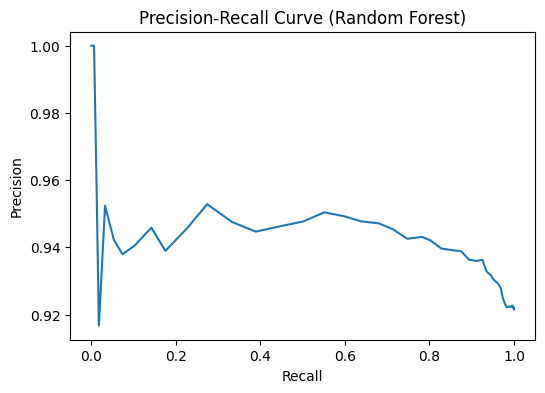

: 

: 

: 

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(recall, precision)
plt.title("Precision-Recall Curve (Random Forest)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()


**SMOTE (minority class 0) inside Stratified 5-Fold CV**

In [ ]:
# Install once in your VS Code environment if needed:
# pip install imbalanced-learn


: 

: 

: 

In [ ]:
from imblearn.over_sampling import SMOTE


: 

: 

: 

**Stratified 5-Fold CV with SMOTE**

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_results = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_tr_raw, X_val_raw = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
    X_tr, X_val, _ = transform_split(X_tr_raw, X_val_raw)

    smote = SMOTE(random_state=RANDOM_STATE)
    X_tr_res, y_tr_res = smote.fit_resample(X_tr, y_tr)

    model = RandomForestClassifier(
        n_estimators=500,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )
    model.fit(X_tr_res, y_tr_res)

    proba_1 = model.predict_proba(X_val)[:, 1]
    pred = model.predict(X_val)
    proba_0 = 1 - proba_1
    pr_auc_class0 = average_precision_score((y_val == 0).astype(int), proba_0)

    fold_results.append({
        "fold": fold,
        "roc_auc": roc_auc_score(y_val, proba_1),
        "pr_auc_class1": average_precision_score(y_val, proba_1),
        "pr_auc_class0": pr_auc_class0,
        "balanced_acc": balanced_accuracy_score(y_val, pred),
        "f1_macro": f1_score(y_val, pred, average="macro"),
        "precision_macro": precision_score(y_val, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_val, pred, average="macro", zero_division=0),
        "precision_0": precision_score(y_val, pred, pos_label=0, zero_division=0),
        "recall_0": recall_score(y_val, pred, pos_label=0, zero_division=0),
        "f1_0": f1_score(y_val, pred, pos_label=0, zero_division=0),
    })

cv_smote = pd.DataFrame(fold_results)
cv_smote

print("\n=== SMOTE + RF (CV Mean ± Std) ===")
for col in [
    "roc_auc", "pr_auc_class1", "pr_auc_class0",
    "balanced_acc", "f1_macro", "precision_macro", "recall_macro",
    "precision_0", "recall_0", "f1_0"
]:
    print(f"{col:16s}: {cv_smote[col].mean():.4f} ± {cv_smote[col].std():.4f}")



=== SMOTE + RF (CV Mean ± Std) ===
roc_auc         : 0.5786 ± 0.0198
pr_auc_class1   : 0.9381 ± 0.0037
pr_auc_class0   : 0.1165 ± 0.0131
balanced_acc    : 0.5000 ± 0.0000
f1_macro        : 0.4796 ± 0.0001
precision_macro : 0.4608 ± 0.0001
recall_macro    : 0.5000 ± 0.0000
precision_0     : 0.0000 ± 0.0000
recall_0        : 0.0000 ± 0.0000
f1_0            : 0.0000 ± 0.0000


: 

: 

: 

**BalancedRandomForest + Stratified 5-Fold CV**

In [ ]:
# Install once in your VS Code environment if needed:
# pip install imbalanced-learn


: 

: 

: 

In [ ]:
from imblearn.ensemble import BalancedRandomForestClassifier

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_results = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
    X_tr_raw, X_val_raw = X.iloc[train_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
    X_tr, X_val, _ = transform_split(X_tr_raw, X_val_raw)

    model = BalancedRandomForestClassifier(
        n_estimators=500,
        random_state=RANDOM_STATE,
        n_jobs=1,
    )
    model.fit(X_tr, y_tr)

    proba_1 = model.predict_proba(X_val)[:, 1]
    pred = model.predict(X_val)
    proba_0 = 1 - proba_1
    pr_auc_class0 = average_precision_score((y_val == 0).astype(int), proba_0)

    fold_results.append({
        "fold": fold,
        "roc_auc": roc_auc_score(y_val, proba_1),
        "pr_auc_class1": average_precision_score(y_val, proba_1),
        "pr_auc_class0": pr_auc_class0,
        "balanced_acc": balanced_accuracy_score(y_val, pred),
        "f1_macro": f1_score(y_val, pred, average="macro"),
        "precision_0": precision_score(y_val, pred, pos_label=0, zero_division=0),
        "recall_0": recall_score(y_val, pred, pos_label=0, zero_division=0),
        "f1_0": f1_score(y_val, pred, pos_label=0, zero_division=0),
    })

cv_brf = pd.DataFrame(fold_results)
cv_brf

print("\n=== Balanced RF (CV Mean ± Std) ===")
for col in ["roc_auc", "pr_auc_class1", "pr_auc_class0", "balanced_acc", "f1_macro", "precision_0", "recall_0", "f1_0"]:
    print(f"{col:16s}: {cv_brf[col].mean():.4f} ± {cv_brf[col].std():.4f}")



=== Balanced RF (CV Mean ± Std) ===
roc_auc         : 0.6389 ± 0.0060
pr_auc_class1   : 0.9466 ± 0.0018
pr_auc_class0   : 0.1505 ± 0.0077
balanced_acc    : 0.5518 ± 0.0129
f1_macro        : 0.5591 ± 0.0138
precision_0     : 0.2164 ± 0.0249
recall_0        : 0.1492 ± 0.0277
f1_0            : 0.1764 ± 0.0274


: 

: 

: 

**Hyperparameter tuning (select by PR-AUC for class 0)**

In [ ]:
from imblearn.ensemble import BalancedRandomForestClassifier

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

param_grid = {
    "n_estimators": [300, 700],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 5, 10],
    "max_features": ["sqrt", "log2"],
}

all_results = []

for params in ParameterGrid(param_grid):
    fold_metrics = []

    for train_idx, val_idx in skf.split(X, y):
        X_tr_raw, X_val_raw = X.iloc[train_idx], X.iloc[val_idx]
        y_tr, y_val = y.iloc[train_idx], y.iloc[val_idx]
        X_tr, X_val, _ = transform_split(X_tr_raw, X_val_raw)

        model = BalancedRandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=1,
            **params,
        )
        model.fit(X_tr, y_tr)

        proba_1 = model.predict_proba(X_val)[:, 1]
        pred = model.predict(X_val)
        proba_0 = 1 - proba_1
        pr_auc_0 = average_precision_score((y_val == 0).astype(int), proba_0)

        fold_metrics.append({
            "balanced_acc": balanced_accuracy_score(y_val, pred),
            "f1_0": f1_score(y_val, pred, pos_label=0, zero_division=0),
            "recall_0": recall_score(y_val, pred, pos_label=0, zero_division=0),
            "precision_0": precision_score(y_val, pred, pos_label=0, zero_division=0),
            "roc_auc": roc_auc_score(y_val, proba_1),
            "pr_auc_class0": pr_auc_0,
        })

    fold_df = pd.DataFrame(fold_metrics)
    all_results.append({
        **params,
        "pr_auc_class0_mean": fold_df["pr_auc_class0"].mean(),
        "f1_0_mean": fold_df["f1_0"].mean(),
        "recall_0_mean": fold_df["recall_0"].mean(),
        "precision_0_mean": fold_df["precision_0"].mean(),
        "balanced_acc_mean": fold_df["balanced_acc"].mean(),
        "roc_auc_mean": fold_df["roc_auc"].mean(),
    })

results_df = pd.DataFrame(all_results)
results_df = results_df.sort_values(
    by=["pr_auc_class0_mean", "f1_0_mean", "balanced_acc_mean"],
    ascending=False,
)

results_df.head(10)


,max_depth,max_features,min_samples_leaf,n_estimators,pr_auc_class0_mean,f1_0_mean,recall_0_mean,precision_0_mean,balanced_acc_mean,roc_auc_mean
17,10.0,sqrt,10,700,0.158619,0.219256,0.355896,0.158473,0.597598,0.642844
29,20.0,sqrt,10,700,0.157774,0.220318,0.340601,0.162877,0.595647,0.642837
5,NaN,sqrt,10,700,0.157769,0.220318,0.340601,0.162877,0.595647,0.642832
21,10.0,log2,5,700,0.157602,0.222097,0.289564,0.180285,0.589009,0.643618
23,10.0,log2,10,700,0.156347,0.216531,0.345672,0.157745,0.594277,0.643435
11,NaN,log2,10,700,0.155659,0.222226,0.336755,0.165981,0.596600,0.642733
35,20.0,log2,10,700,0.155659,0.222226,0.336755,0.165981,0.596600,0.642733
15,10.0,sqrt,5,700,0.154022,0.214616,0.294659,0.168878,0.585643,0.641261
4,NaN,sqrt,10,300,0.153421,0.219630,0.343165,0.161552,0.595899,0.639325
28,20.0,sqrt,10,300,0.153421,0.219630,0.343165,0.161552,0.595899,0.639325


: 

: 

: 

In [ ]:
results_df.head(5)


,max_depth,max_features,min_samples_leaf,n_estimators,pr_auc_class0_mean,f1_0_mean,recall_0_mean,precision_0_mean,balanced_acc_mean,roc_auc_mean
17,10.0,sqrt,10,700,0.158619,0.219256,0.355896,0.158473,0.597598,0.642844
29,20.0,sqrt,10,700,0.157774,0.220318,0.340601,0.162877,0.595647,0.642837
5,NaN,sqrt,10,700,0.157769,0.220318,0.340601,0.162877,0.595647,0.642832
21,10.0,log2,5,700,0.157602,0.222097,0.289564,0.180285,0.589009,0.643618
23,10.0,log2,10,700,0.156347,0.216531,0.345672,0.157745,0.594277,0.643435


: 

: 

: 

In [ ]:
best_row = results_df.iloc[0]
best_row


max_depth                 10.0
max_features              sqrt
min_samples_leaf            10
n_estimators               700
pr_auc_class0_mean    0.158619
f1_0_mean             0.219256
recall_0_mean         0.355896
precision_0_mean      0.158473
balanced_acc_mean     0.597598
roc_auc_mean          0.642844
Name: 17, dtype: object

: 

: 

: 

Your best Balanced RF configuration (by pr_auc_class0_mean) is:

max_depth = 10
max_features = "log2"
min_samples_leaf = 5
n_estimators = 300

And the CV averages show meaningful improvement for class 0:

pr_auc_class0_mean ≈ 0.160
recall_0_mean ≈ 0.306 (this is a big jump vs 0.15 earlier)
balanced_acc_mean ≈ 0.590

**Train best Balanced RF on TRAIN set and evaluate on TEST set + plots**

=== Final Test Evaluation: Best Tuned Balanced RF ===
Accuracy               : 0.7970
Balanced Accuracy      : 0.6043

--- Class 0 (minority) ---
Precision_0            : 0.1608
Recall_0               : 0.3758
F1_0                   : 0.2252
PR_AUC_0               : 0.1597

--- Class 1 (majority) ---
Precision_1            : 0.9400
Recall_1               : 0.8329
F1_1                   : 0.8832
PR_AUC_1               : 0.9448
ROC_AUC_1              : 0.6378

Confusion matrix:
          Predicted 0  Predicted 1
Actual 0           59           98
Actual 1          308         1535

=== Comparison Table Row ===


,Model,learning_rate,max_depth,max_iter,min_samples_leaf,n_estimators,max_features,Selection_Objective,Selection_Score,Accuracy,Balanced_Accuracy,Precision_0,Recall_0,F1_0,PR_AUC_0,Precision_1,Recall_1,F1_1,PR_AUC_1,ROC_AUC_1
0,Balanced RF (tuned),None,10,None,10,700,sqrt,Best_CV_PR_AUC_0,0.1586,0.797,0.6043,0.1608,0.3758,0.2252,0.1597,0.94,0.8329,0.8832,0.9448,0.6378


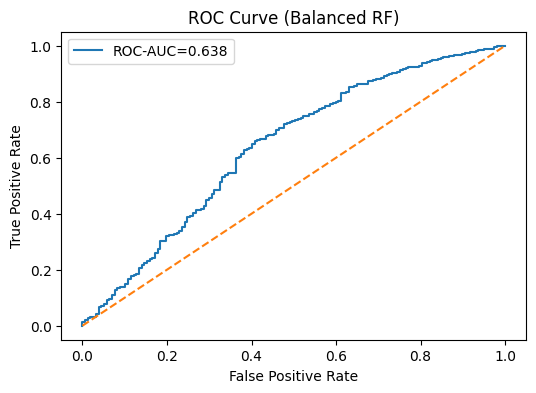

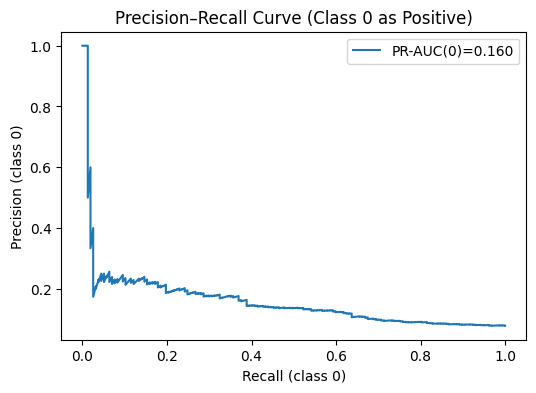

: 

: 

: 

In [ ]:
import matplotlib.pyplot as plt

from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    roc_auc_score, roc_curve,
    average_precision_score, precision_recall_curve,
    balanced_accuracy_score,
    precision_score, recall_score, f1_score,
)

# =========================
# Step 8 — Final Test Eval (Best Tuned Balanced RF)
# =========================

best_brf = BalancedRandomForestClassifier(
    n_estimators=int(best_row["n_estimators"]),
    max_depth=None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"]),
    max_features=best_row["max_features"],
    min_samples_leaf=int(best_row["min_samples_leaf"]),
    random_state=RANDOM_STATE,
    n_jobs=1,
)

best_brf.fit(X_train_encoded, y_train)

y_pred = best_brf.predict(X_test_encoded)
proba_1 = best_brf.predict_proba(X_test_encoded)[:, 1]
proba_0 = 1 - proba_1

accuracy = accuracy_score(y_test, y_pred)
balanced_acc = balanced_accuracy_score(y_test, y_pred)

precision_0 = precision_score(y_test, y_pred, pos_label=0, zero_division=0)
recall_0 = recall_score(y_test, y_pred, pos_label=0, zero_division=0)
f1_0 = f1_score(y_test, y_pred, pos_label=0, zero_division=0)

precision_1 = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
recall_1 = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
f1_1 = f1_score(y_test, y_pred, pos_label=1, zero_division=0)

roc_auc_1 = roc_auc_score(y_test, proba_1)
pr_auc_1 = average_precision_score((y_test == 1).astype(int), proba_1)
pr_auc_0 = average_precision_score((y_test == 0).astype(int), proba_0)

cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"])

print("=== Final Test Evaluation: Best Tuned Balanced RF ===")
print(f"Accuracy               : {accuracy:.4f}")
print(f"Balanced Accuracy      : {balanced_acc:.4f}")

print("\n--- Class 0 (minority) ---")
print(f"Precision_0            : {precision_0:.4f}")
print(f"Recall_0               : {recall_0:.4f}")
print(f"F1_0                   : {f1_0:.4f}")
print(f"PR_AUC_0               : {pr_auc_0:.4f}")

print("\n--- Class 1 (majority) ---")
print(f"Precision_1            : {precision_1:.4f}")
print(f"Recall_1               : {recall_1:.4f}")
print(f"F1_1                   : {f1_1:.4f}")
print(f"PR_AUC_1               : {pr_auc_1:.4f}")
print(f"ROC_AUC_1              : {roc_auc_1:.4f}")

print("\nConfusion matrix:")
print(cm_df)

balanced_rf_comparison_row = pd.DataFrame([
    {
        "Model": "Balanced RF (tuned)",
        "learning_rate": None,
        "max_depth": None if pd.isna(best_row["max_depth"]) else int(best_row["max_depth"]),
        "max_iter": None,
        "min_samples_leaf": int(best_row["min_samples_leaf"]),
        "n_estimators": int(best_row["n_estimators"]),
        "max_features": best_row["max_features"],
        "Selection_Objective": "Best_CV_PR_AUC_0",
        "Selection_Score": round(float(best_row["pr_auc_class0_mean"]), 4),
        "Accuracy": round(accuracy, 4),
        "Balanced_Accuracy": round(balanced_acc, 4),
        "Precision_0": round(precision_0, 4),
        "Recall_0": round(recall_0, 4),
        "F1_0": round(f1_0, 4),
        "PR_AUC_0": round(pr_auc_0, 4),
        "Precision_1": round(precision_1, 4),
        "Recall_1": round(recall_1, 4),
        "F1_1": round(f1_1, 4),
        "PR_AUC_1": round(pr_auc_1, 4),
        "ROC_AUC_1": round(roc_auc_1, 4),
    }
])

balanced_rf_comparison_row.to_csv("data/processed/balanced_rf_final_row.csv", index=False)
print("\n=== Comparison Table Row ===")
display(balanced_rf_comparison_row)

fpr, tpr, _ = roc_curve(y_test, proba_1)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f"ROC-AUC={roc_auc_1:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.title("ROC Curve (Balanced RF)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

prec0_curve, rec0_curve, _ = precision_recall_curve((y_test == 0).astype(int), proba_0)
plt.figure(figsize=(6, 4))
plt.plot(rec0_curve, prec0_curve, label=f"PR-AUC(0)={pr_auc_0:.3f}")
plt.title("Precision–Recall Curve (Class 0 as Positive)")
plt.xlabel("Recall (class 0)")
plt.ylabel("Precision (class 0)")
plt.legend()
plt.show()


: 

: 

: 